# Bank Customer Churn

owner: onionsthe1st

In [92]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt



# Bronze

In [93]:
customer_churn = pd.read_csv("Customer-Churn-Records.csv")
customer_churn

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Complain,Satisfaction Score,Card Type,Point Earned
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1,1,2,DIAMOND,464
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0,1,3,DIAMOND,456
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1,1,3,DIAMOND,377
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0,0,5,GOLD,350
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0,0,5,GOLD,425
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,9996,15606229,Obijiaku,771,France,Male,39,5,0.00,2,1,0,96270.64,0,0,1,DIAMOND,300
9996,9997,15569892,Johnstone,516,France,Male,35,10,57369.61,1,1,1,101699.77,0,0,5,PLATINUM,771
9997,9998,15584532,Liu,709,France,Female,36,7,0.00,1,0,1,42085.58,1,1,3,SILVER,564
9998,9999,15682355,Sabbatini,772,Germany,Male,42,3,75075.31,2,1,0,92888.52,1,1,2,GOLD,339


### Checking for errors in the dataset

In [94]:
print(customer_churn.info())
print("Summary of my dataset (Mathematically): \n",customer_churn.describe())
print("Checking for blank cells:\n",customer_churn.isnull().sum())
print("Checking for duplicates:\n",customer_churn.duplicated().sum())


<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 18 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   RowNumber           10000 non-null  int64  
 1   CustomerId          10000 non-null  int64  
 2   Surname             10000 non-null  str    
 3   CreditScore         10000 non-null  int64  
 4   Geography           10000 non-null  str    
 5   Gender              10000 non-null  str    
 6   Age                 10000 non-null  int64  
 7   Tenure              10000 non-null  int64  
 8   Balance             10000 non-null  float64
 9   NumOfProducts       10000 non-null  int64  
 10  HasCrCard           10000 non-null  int64  
 11  IsActiveMember      10000 non-null  int64  
 12  EstimatedSalary     10000 non-null  float64
 13  Exited              10000 non-null  int64  
 14  Complain            10000 non-null  int64  
 15  Satisfaction Score  10000 non-null  int64  
 16  Card Type       

there are no errors, its a clean data, the datatypes are what they should be, there are no blank cells, there are no duplicte rows, there

## Checking for Correlation between all features

In [95]:
pd.crosstab( customer_churn["Exited"], customer_churn["IsActiveMember"])
correlation = customer_churn.corr(numeric_only=True)

correlation


,RowNumber,CustomerId,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Complain,Satisfaction Score,Point Earned
RowNumber,1.000000,0.004202,0.005840,0.000783,-0.006495,-0.009067,0.007246,0.000599,0.012044,-0.005988,-0.016140,-0.016957,0.009289,0.002360
CustomerId,0.004202,1.000000,0.005308,0.009497,-0.014883,-0.012419,0.016972,-0.014025,0.001665,0.015271,-0.006203,-0.007293,-0.000865,-0.013076
CreditScore,0.005840,0.005308,1.000000,-0.003965,0.000842,0.006268,0.012238,-0.005458,0.025651,-0.001384,-0.026771,-0.027048,-0.012599,0.000077
Age,0.000783,0.009497,-0.003965,1.000000,-0.009997,0.028308,-0.030680,-0.011721,0.085472,-0.007201,0.285296,0.283530,-0.000876,0.002222
Tenure,-0.006495,-0.014883,0.000842,-0.009997,1.000000,-0.012254,0.013444,0.022583,-0.028362,0.007784,-0.013656,-0.013047,0.008663,-0.010196
Balance,-0.009067,-0.012419,0.006268,0.028308,-0.012254,1.000000,-0.304180,-0.014858,-0.010084,0.012797,0.118577,0.119124,-0.002588,0.014608
NumOfProducts,0.007246,0.016972,0.012238,-0.030680,0.013444,-0.304180,1.000000,0.003183,0.009612,0.014204,-0.047611,-0.046357,-0.011394,-0.015330
HasCrCard,0.000599,-0.014025,-0.005458,-0.011721,0.022583,-0.014858,0.003183,1.000000,-0.011866,-0.009933,-0.006976,-0.007095,-0.000212,-0.011041
IsActiveMember,0.012044,0.001665,0.025651,0.085472,-0.028362,-0.010084,0.009612,-0.011866,1.000000,-0.011421,-0.156356,-0.154741,0.010236,-0.004983
EstimatedSalary,-0.005988,0.015271,-0.001384,-0.007201,0.007784,0.012797,0.014204,-0.009933,-0.011421,1.000000,0.012490,0.012494,-0.013747,-0.001515


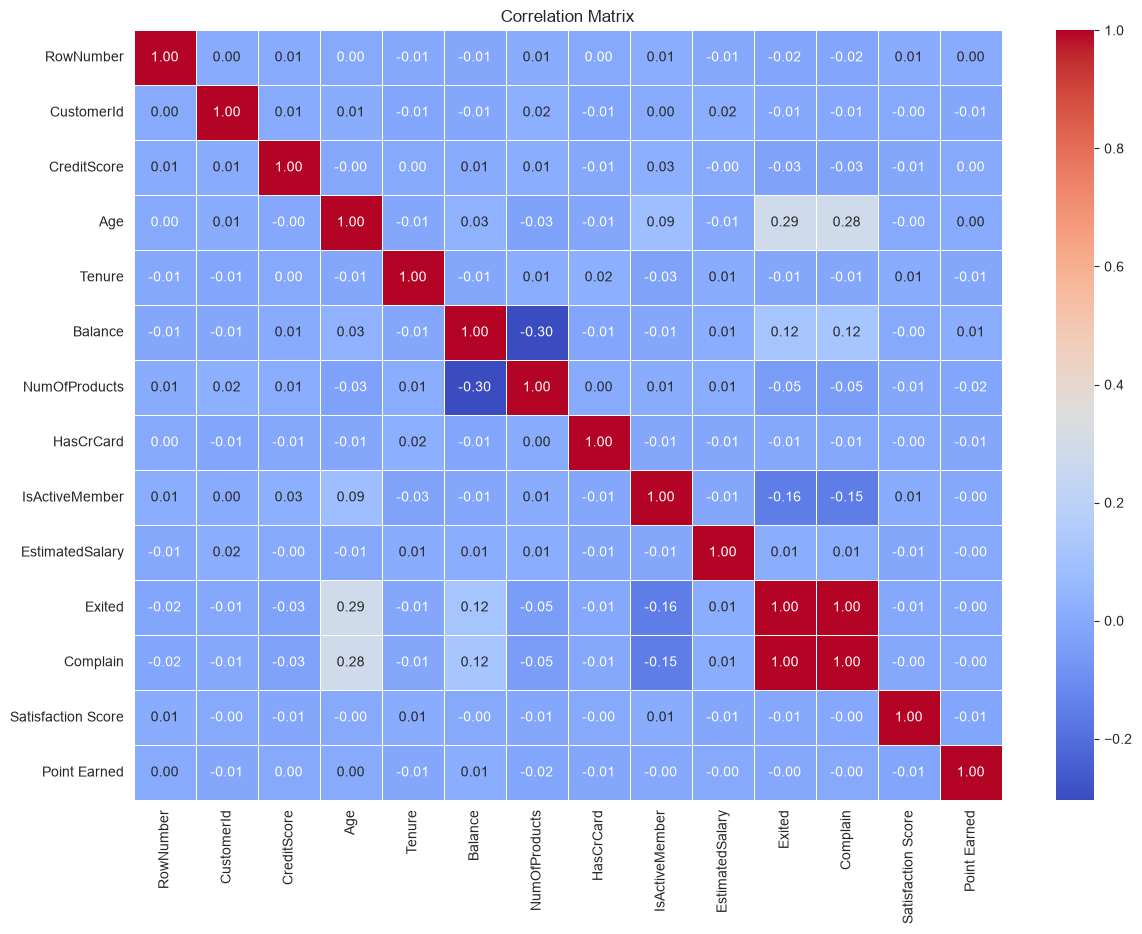

In [96]:
plt.figure(figsize=(14, 10))

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title('Correlation Matrix')
plt.show()

## checking the correlation to the target (y)

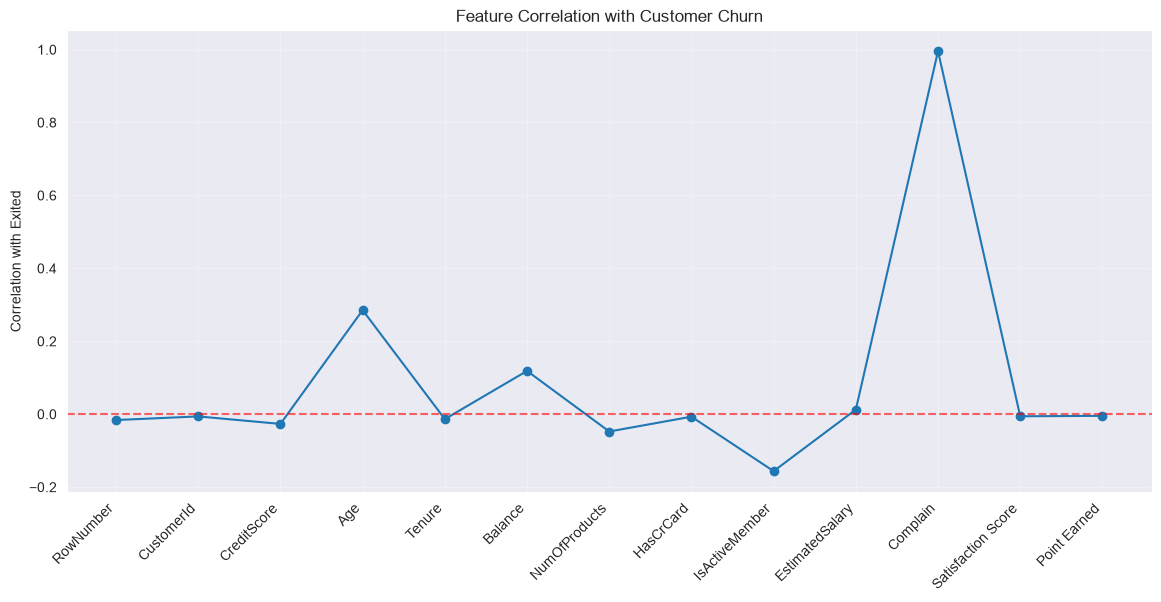

In [97]:
corr = customer_churn.corr(numeric_only=True)['Exited'].drop('Exited')

plt.figure(figsize=(14, 6))

plt.plot(corr.index, corr.values, marker='o')

plt.axhline(y=0, color='red', linestyle='--', alpha=0.6)

plt.xticks(rotation=45, ha='right')
plt.ylabel('Correlation with Exited')
plt.title('Feature Correlation with Customer Churn')
plt.grid(alpha=0.3)

# plt.tight_layout()
plt.show()

## checking for target(data) leak

According to my correlation tests, complain and exited were too identical, it might cause a leak in the data set, and the model will not learn the patterns that way

In [98]:
pd.crosstab(customer_churn['Complain'], customer_churn['Exited'])

Exited,0,1
Complain,,
0,7952,4
1,10,2034


# Ml

In [99]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.compose import ColumnTransformer,make_column_selector
from sklearn.preprocessing import StandardScaler,OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score,confusion_matrix,classification_report
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.utils.class_weight import compute_sample_weight

## Model A with complain feature (Testing with Logistics Regression)

In [100]:
training_df = customer_churn.drop(
    columns=['RowNumber', 'Surname', 'CustomerId']
)

In [101]:
numerical_cols = training_df.select_dtypes(include=['int64', 'float64']).columns.tolist()
categorical_cols = training_df.select_dtypes(include=['object', 'string']).columns.tolist()

In [102]:
X = training_df.drop("Exited", axis=1)
y = training_df["Exited"]

In [103]:
X_train,X_test, y_train, y_test = train_test_split(X,y, test_size=0.2, random_state=10, stratify=y)

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), make_column_selector(dtype_include=["int64", "float64"])),
        ('cat', OneHotEncoder(handle_unknown='ignore'), make_column_selector(dtype_include=["object", "string"])),
    ]
)

model_A = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(max_iter=1000))
])

model_A.fit(X_train, y_train)

prediction = model_A.predict(X_test)

print("Accuracy:", accuracy_score(y_test, prediction))

print("\nClassification Report:")
print(classification_report(y_test, prediction))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, prediction))

Accuracy: 0.9975

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00      1592
           1       0.99      1.00      0.99       408

    accuracy                           1.00      2000
   macro avg       0.99      1.00      1.00      2000
weighted avg       1.00      1.00      1.00      2000


Confusion Matrix:
[[1587    5]
 [   0  408]]


because the complain feature is in thius traning dataset, there might be data leak.

## Model B without complain feature in the training dataset(Testing With Logistics regression)

In [104]:
training_df_2 = customer_churn.drop(
    columns=["CustomerId", "RowNumber", "Surname", "Complain"]
)

In [105]:
X = training_df_2.drop('Exited',axis=1)
y = training_df_2['Exited']

In [106]:
X_train,X_test, y_train, y_test = train_test_split(X,y, test_size=0.2, random_state=10, stratify=y)

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), make_column_selector(dtype_include=["int64", "float64"])),
        ('cat', OneHotEncoder(handle_unknown='ignore'), make_column_selector(dtype_include=["object", "string"])),
    ]
)

model_B = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(max_iter=1000))
])

model_B.fit(X_train, y_train)

prediction = model_B.predict(X_test)

print("Accuracy:", accuracy_score(y_test, prediction))

print("\nClassification Report:")
print(classification_report(y_test, prediction))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, prediction))

print(y_test.head(15))
print(prediction)

Accuracy: 0.815

Classification Report:
              precision    recall  f1-score   support

           0       0.83      0.97      0.89      1592
           1       0.63      0.22      0.33       408

    accuracy                           0.81      2000
   macro avg       0.73      0.59      0.61      2000
weighted avg       0.79      0.81      0.78      2000


Confusion Matrix:
[[1539   53]
 [ 317   91]]
2495    1
2252    0
1600    0
2152    1
2035    0
8102    0
2716    0
5704    1
964     1
5689    0
108     0
9215    1
2587    0
4959    0
6343    1
Name: Exited, dtype: int64
[1 0 0 ... 0 0 0]


the f1 score dropped significantly without the complain feature in the training dataset. THIS IS NOT A GOOD ALGORITHM TO USE FOR THIS DATASET, its probably not linear

In [107]:
feature_names = model_A.named_steps['preprocessor'].get_feature_names_out()
coefficients = model_A.named_steps['classifier'].coef_[0]

importance = pd.DataFrame({
    'Feature': feature_names,
    'Coefficient': coefficients,
    'Abs_Coefficient': abs(coefficients)
})

importance = importance.sort_values(
    by='Abs_Coefficient',
    ascending=False
)

print(importance)

                    Feature  Coefficient  Abs_Coefficient
8             num__Complain     5.147299         5.147299
12   cat__Geography_Germany    -1.013347         1.013347
14       cat__Gender_Female    -0.986741         0.986741
15         cat__Gender_Male    -0.872058         0.872058
1                  num__Age     0.703583         0.703583
17      cat__Card Type_GOLD    -0.673907         0.673907
6       num__IsActiveMember    -0.666340         0.666340
18  cat__Card Type_PLATINUM    -0.634322         0.634322
11    cat__Geography_France    -0.504091         0.504091
19    cat__Card Type_SILVER    -0.405382         0.405382
13     cat__Geography_Spain    -0.341360         0.341360
10        num__Point Earned    -0.292825         0.292825
3              num__Balance     0.235914         0.235914
4        num__NumOfProducts    -0.227234         0.227234
16   cat__Card Type_DIAMOND    -0.145188         0.145188
2               num__Tenure    -0.117326         0.117326
9   num__Satis

This proved that the complain feature was holding so much importance  im model A

In [108]:
feature_names = model_B.named_steps['preprocessor'].get_feature_names_out()
coefficients = model_B.named_steps['classifier'].coef_[0]

importance = pd.DataFrame({
    'Feature': feature_names,
    'Coefficient': coefficients,
    'Abs_Coefficient': abs(coefficients)
})

importance = importance.sort_values(
    by='Abs_Coefficient',
    ascending=False
)

print(importance)

                    Feature  Coefficient  Abs_Coefficient
1                  num__Age     0.747203         0.747203
14         cat__Gender_Male    -0.642010         0.642010
6       num__IsActiveMember    -0.519661         0.519661
10    cat__Geography_France    -0.506116         0.506116
12     cat__Geography_Spain    -0.473406         0.473406
16      cat__Card Type_GOLD    -0.264562         0.264562
11   cat__Geography_Germany     0.236189         0.236189
18    cat__Card Type_SILVER    -0.209924         0.209924
17  cat__Card Type_PLATINUM    -0.202660         0.202660
3              num__Balance     0.140367         0.140367
13       cat__Gender_Female    -0.101323         0.101323
4        num__NumOfProducts    -0.096523         0.096523
15   cat__Card Type_DIAMOND    -0.066186         0.066186
2               num__Tenure    -0.062095         0.062095
0          num__CreditScore    -0.057854         0.057854
7      num__EstimatedSalary     0.031315         0.031315
9         num_

## Random Forest regression

In [109]:
training_df_3 = customer_churn.drop(['CustomerId', 'RowNumber', 'Surname', 'Complain'], axis=1)

In [110]:
X = training_df_3.drop('Exited',axis=1)
y= training_df_3['Exited']

In [111]:
X_train, X_test, y_train,y_test = train_test_split(X,y, test_size=0.2, random_state=10, stratify=y)


preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), make_column_selector(dtype_include=["int64", "float64"])),
        ('cat', OneHotEncoder(handle_unknown='ignore'), make_column_selector(dtype_include=["object", "string"])),
    ]
)

model_rf = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(
        n_estimators=300,
        class_weight='balanced',
        random_state=10
    ))
])

model_rf.fit(X_train, y_train)

prediction_rf = model_rf.predict(X_test)

print("Accuracy:", accuracy_score(y_test, prediction_rf))

print("\nClassification Report:")
print(classification_report(y_test, prediction_rf))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, prediction_rf))

Accuracy: 0.8635

Classification Report:
              precision    recall  f1-score   support

           0       0.90      0.93      0.92      1592
           1       0.68      0.62      0.65       408

    accuracy                           0.86      2000
   macro avg       0.79      0.77      0.78      2000
weighted avg       0.86      0.86      0.86      2000


Confusion Matrix:
[[1474  118]
 [ 155  253]]


random forest classifier with a balanced class weight gives the best f1 score for now, an f1 score of 65%, this is a much better model that the last one. the dataset might not be linear, maybe thats why i got a low precision and recall rate, let me check for linearity.

## Churn rate ( non linear check)

checking if my dataset is linear, so as to know the type of algorithm to use, rather than just trying


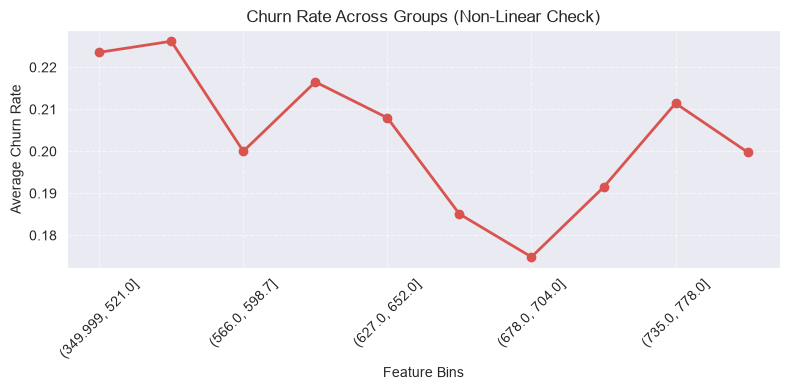

In [112]:
import pandas as pd
import matplotlib.pyplot as plt

training_df_3['bin'] = pd.qcut(training_df_3['CreditScore'], q=10, duplicates='drop')
churn_by_bin = training_df_3.groupby('bin', observed=False)['Exited'].mean()

plt.figure(figsize=(8, 4))
churn_by_bin.plot(kind='line', marker='o', color='#d9534f', linewidth=2)
plt.title('Churn Rate Across Groups (Non-Linear Check)')
plt.ylabel('Average Churn Rate')
plt.xlabel('Feature Bins')
plt.xticks(rotation=45)
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()


### After checking for linearity, my dataset will not give me accurate predictions with logistics regression which is linear, Tree based algorithms will work well to predict the churn rate.

i'll be testing with other tree based algorithms to establish a base line

In [113]:
training_df_3 = customer_churn.drop(['CustomerId', 'RowNumber', 'Surname', 'Complain'], axis=1)


In [114]:
X = training_df_3.drop('Exited',axis=1)
y= training_df_3['Exited']

# Gradient Boosting Classifier

In [115]:
X_train, X_test, y_train,y_test = train_test_split(X,y, test_size=0.2, random_state=10, stratify=y)


preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), make_column_selector(dtype_include=["int64", "float64"])),
        ('cat', OneHotEncoder(handle_unknown='ignore'), make_column_selector(dtype_include=["object", "string"])),
    ]
)
weights = compute_sample_weight(class_weight='balanced', y=y_train)
model_gb = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', GradientBoostingClassifier(
        n_estimators=300,
        random_state=10,
        learning_rate=0.05,
        max_depth=4
    ))
])

model_gb.fit(X_train, y_train, classifier__sample_weight=weights)
prediction_gb = model_gb.predict(X_test)

prediction_gb = model_gb.predict(X_test)

print("Accuracy:", accuracy_score(y_test, prediction_gb))

print("\nClassification Report:")
print(classification_report(y_test, prediction_gb))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, prediction_gb))

Accuracy: 0.805

Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.82      0.87      1592
           1       0.52      0.75      0.61       408

    accuracy                           0.81      2000
   macro avg       0.72      0.78      0.74      2000
weighted avg       0.84      0.81      0.82      2000


Confusion Matrix:
[[1304  288]
 [ 102  306]]


Gotten a better f1 score for churning, gbc will be my algorithm for this project, a recall rate of 75% is not bad, while i can get a better recall rate, it will sacrifice my precision, while it will detect more likely to churn customers, it will also detect more customers that are likely to stay and will just waste time and resources reaching out to the faslely detected negatives.

## Test 1 row in my data

In [116]:
customer = X_test.iloc[[0]]

prediction = model_gb.predict(customer)
probability = model_gb.predict_proba(customer)

print("Actual outcome:", y_test.iloc[0])
print("Predicted outcome:", prediction[0])
print("Probability of staying:", probability[0][0])
print("Probability of churning:", probability[0][1])

Actual outcome: 1
Predicted outcome: 1
Probability of staying: 0.018885597842033475
Probability of churning: 0.9811144021579665


## Test new Customers

In [117]:
customer = pd.DataFrame([{
    'CreditScore': 350,
    'Geography': 'Nigeria',
    'Gender': 'Male',
    'Age': 12,
    'Tenure': 9,
    'Balance': 12000,
    'NumOfProducts': 2,
    'HasCrCard': 1,
    'IsActiveMember': 1,
    'EstimatedSalary': 85000,
    'Complain': 1,
    'Satisfaction Score': 5,
    'Card Type': 'PLATINUM',
    'Point Earned': 600
}])

prediction = model_gb.predict(customer)
probability = model_gb.predict_proba(customer)

if prediction[0] == 0:
    print("Probability of Churning is low")
else:
    print("Probability of Churning is high")


print("Prediction:", prediction[0])
print("Churn probability:", probability[0][1])

Probability of Churning is low
Prediction: 0
Churn probability: 0.3632713362693248


## saving my model to a pkl file so that a visualization can be created

In [118]:
import joblib

joblib.dump(model_gb, "Bank_Customer_Churn.pkl")

churn_gb = joblib.load("Bank_Customer_Churn.pkl")

churn_gb.predict(customer)

array([0])

In [119]:
churn_gb.predict_proba(customer)[:, 1]

array([0.36327134])

In [120]:

features = [
    'CreditScore', 'Geography', 'Gender', 'Age', 'Tenure',
    'Balance', 'NumOfProducts', 'HasCrCard',
    'IsActiveMember', 'EstimatedSalary','Satisfaction Score',
    'Card Type', 'Point Earned'
]

customer_features = customer_churn[features]


customer_churn['Predicted_Churn'] = churn_gb.predict(customer_features)

customer_churn['Churn_Probability'] = churn_gb.predict_proba(customer_features)[:, 1]


customer_churn.to_csv("Bank_churn_predictions.csv", index=False)